# 04 Modeling and Evaluation
Goal: predict at booking time whether a booking will be canceled, using only information the hotel has at that moment.

I start with a baseline, then simple models (Logistic Regression, Decision Tree), then more complex ones (Random Forest, Gradient Boosting). All of them use the same sklearn `Pipeline` and the same metrics.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, cross_val_predict, train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, roc_curve, precision_recall_curve, confusion_matrix,
                             ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

import warnings
warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
FIG = "../reports/figures/"
BLUE, ORANGE, GREY, GREEN = "#3B6EA8", "#E07B39", "#9AA0A6", "#4E9A6B"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10})
df = pd.read_csv("../data/hotel_bookings_clean.csv", parse_dates=["arrival_date"])
results = {}

## 1. Features
Only columns known at booking time.

In [2]:
CAT = ["hotel", "meal", "country_group", "market_segment", "distribution_channel",
       "reserved_room_type", "deposit_type", "customer_type"]
NUM = ["lead_time", "arrival_month", "arrival_date_week_number", "arrival_date_day_of_month", "arrival_dayofweek",
       "stays_in_weekend_nights", "stays_in_week_nights", "total_nights", "adults", "children", "babies",
       "total_guests", "is_family", "is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled",
       "days_in_waiting_list", "adr", "total_of_special_requests", "has_agent", "has_company"]
LEAKY = ["reservation_status", "reservation_status_date", "assigned_room_type",
         "booking_changes", "required_car_parking_spaces"]
TARGET = "is_canceled"
print(len(CAT), "categorical +", len(NUM), "numeric features. Excluded (leaky):", LEAKY)

8 categorical + 21 numeric features. Excluded (leaky): ['reservation_status', 'reservation_status_date', 'assigned_room_type', 'booking_changes', 'required_car_parking_spaces']


## 2. Train/test split
I train on arrivals in 2015–2016 and test on 2017 (Jan–Aug), the same way a hotel would learn from past bookings to predict new ones. This also keeps copies of the same group booking out of both sets.

For cross-validation I use 5 folds grouped by arrival week, so all copies of a group booking stay in the same fold. A normal random K-fold gives scores that are too high (check (d) in section 10). I use the 2017 test set only once, at the end.

In [3]:
train = df[df["arrival_date"] < "2017-01-01"]
test = df[df["arrival_date"] >= "2017-01-01"]
X_train, y_train = train[CAT + NUM], train[TARGET]
X_test, y_test = test[CAT + NUM], test[TARGET]
print(f"Train: {len(train):,} rows ({y_train.mean():.1%} canceled)   Test: {len(test):,} rows ({y_test.mean():.1%} canceled)")

Train: 78,587 rows (36.2% canceled)   Test: 40,619 rows (38.7% canceled)


## 3. Pipelines
Impute, then encode/scale, then the model. Because it's all one pipeline, preprocessing only learns from the training data.

In [4]:
def make_pre(scale):
    num_steps = [("impute", SimpleImputer(strategy="median"))] + ([("scale", StandardScaler())] if scale else [])
    return ColumnTransformer([
        ("num", Pipeline(num_steps), NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), CAT),
    ])

models = {
    "Baseline (always 'not canceled')": Pipeline([("pre", make_pre(False)), ("model", DummyClassifier(strategy="prior"))]),
    "Logistic Regression": Pipeline([("pre", make_pre(True)), ("model", LogisticRegression(max_iter=2000, C=1.0))]),
    "Decision Tree (depth 8)": Pipeline([("pre", make_pre(False)), ("model", DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, random_state=SEED))]),
    "Random Forest": Pipeline([("pre", make_pre(False)), ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=SEED))]),
    "Gradient Boosting": Pipeline([("pre", make_pre(False)), ("model", HistGradientBoostingClassifier(max_iter=400, learning_rate=0.08, random_state=SEED))]),
}

### Business rule baseline
Without a model, a manager might flag bookings that are Non Refund, made more than 90 days ahead, or from a guest who canceled before. The model has to beat this.

In [5]:
def rule(X):
    return ((X["deposit_type"] == "Non Refund") | (X["lead_time"] > 90) | (X["previous_cancellations"] > 0)).astype(int)

## 4. Cross-validation

In [6]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
groups = train["arrival_date"].dt.strftime("%G-%V")   # ISO year-week of arrival
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "f1": "f1", "recall": "recall", "precision": "precision"}
cv_rows = []
for name, pipe in models.items():
    s = cross_validate(pipe, X_train, y_train, groups=groups, cv=cv, scoring=scoring, n_jobs=1)
    cv_rows.append({"model": name, **{k: s[f"test_{k}"].mean() for k in scoring}, "roc_auc_std": s["test_roc_auc"].std()})
    print(f"{name:35s} ROC-AUC {s['test_roc_auc'].mean():.3f} ± {s['test_roc_auc'].std():.3f}")
cv_df = pd.DataFrame(cv_rows).set_index("model").round(3)
cv_df.to_csv("../reports/results_cv.csv")
cv_df

Baseline (always 'not canceled')    ROC-AUC 0.500 ± 0.000


Logistic Regression                 ROC-AUC 0.882 ± 0.016


Decision Tree (depth 8)             ROC-AUC 0.906 ± 0.011


Random Forest                       ROC-AUC 0.926 ± 0.011


Gradient Boosting                   ROC-AUC 0.926 ± 0.011


,roc_auc,pr_auc,f1,recall,precision,roc_auc_std
model,,,,,,
Baseline (always 'not canceled'),0.500,0.362,0.000,0.000,0.000,0.000
Logistic Regression,0.882,0.843,0.705,0.615,0.826,0.016
Decision Tree (depth 8),0.906,0.861,0.760,0.732,0.791,0.011
Random Forest,0.926,0.899,0.781,0.712,0.866,0.011
Gradient Boosting,0.926,0.897,0.783,0.734,0.840,0.011


I choose the model with the best cross-validated PR-AUC, because it focuses on the canceled class. I don't choose by test score.

In [7]:
best_name = cv_df.drop(index="Baseline (always 'not canceled')")["pr_auc"].idxmax()
print("Selected model:", best_name)

Selected model: Random Forest


## 5. Test on 2017

In [8]:
def scores(y, p, thr=0.5):
    yhat = (p >= thr).astype(int)
    return {"accuracy": accuracy_score(y, yhat), "precision": precision_score(y, yhat, zero_division=0),
            "recall": recall_score(y, yhat), "f1": f1_score(y, yhat),
            "roc_auc": roc_auc_score(y, p) if len(np.unique(p)) > 1 else 0.5, "pr_auc": average_precision_score(y, p)}

fitted, probs, test_rows = {}, {}, []
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    probs[name] = pipe.predict_proba(X_test)[:, 1]
    test_rows.append({"model": name, **scores(y_test, probs[name])})
r = rule(X_test)
test_rows.insert(1, {"model": "Business rule (NonRefund / lead>90 / prev. cancel)", **scores(y_test, r.values.astype(float))})
test_df = pd.DataFrame(test_rows).set_index("model").round(3)
test_df.to_csv("../reports/results_test.csv")
test_df

,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
Baseline (always 'not canceled'),0.613,0.000,0.000,0.000,0.500,0.387
Business rule (NonRefund / lead>90 / prev. cancel),0.626,0.513,0.671,0.582,0.635,0.472
Logistic Regression,0.760,0.810,0.496,0.615,0.837,0.797
Decision Tree (depth 8),0.767,0.755,0.591,0.663,0.825,0.762
Random Forest,0.766,0.793,0.537,0.640,0.843,0.800
Gradient Boosting,0.769,0.779,0.563,0.654,0.841,0.799


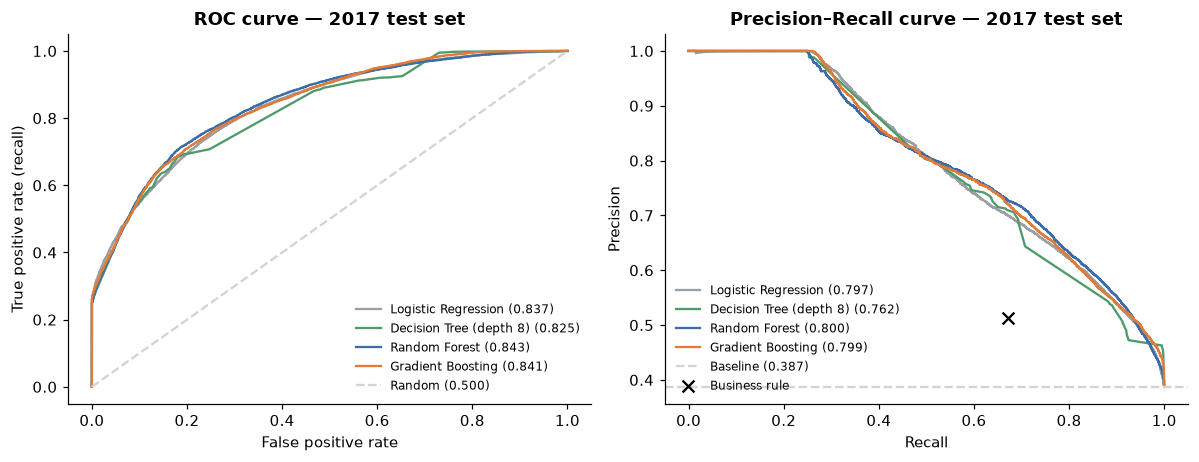

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
palette = {"Logistic Regression": GREY, "Decision Tree (depth 8)": GREEN, "Random Forest": BLUE, "Gradient Boosting": ORANGE}
for name, color in palette.items():
    fpr, tpr, _ = roc_curve(y_test, probs[name]); ax[0].plot(fpr, tpr, color=color, label=f"{name} ({roc_auc_score(y_test, probs[name]):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, probs[name]); ax[1].plot(rc, pr, color=color, label=f"{name} ({average_precision_score(y_test, probs[name]):.3f})")
ax[0].plot([0, 1], [0, 1], ls="--", color="lightgray", label="Random (0.500)")
ax[1].axhline(y_test.mean(), ls="--", color="lightgray", label=f"Baseline ({y_test.mean():.3f})")
rp = scores(y_test, r.values.astype(float))
ax[1].scatter(rp["recall"], rp["precision"], color="black", marker="x", s=60, zorder=5, label="Business rule")
ax[0].set(title="ROC curve — 2017 test set", xlabel="False positive rate", ylabel="True positive rate (recall)")
ax[1].set(title="Precision–Recall curve — 2017 test set", xlabel="Recall", ylabel="Precision")
for a in ax: a.legend(frameon=False, fontsize=8, loc="lower right" if a is ax[0] else "lower left")
plt.tight_layout(); plt.savefig(FIG + "fig11_roc_pr.png", bbox_inches="tight"); plt.show()

## 6. Threshold
The model gives a probability, so I need a cut-off. I choose it on out-of-fold training predictions and then check it on 2017.

Cost assumptions (easy to change):
- Catching a cancellation lets the hotel resell the room, so I get back 50% of the booking value (ADR × nights).
- Flagging a guest who would have come (deposit request, overbooking) costs 20% of the booking value.

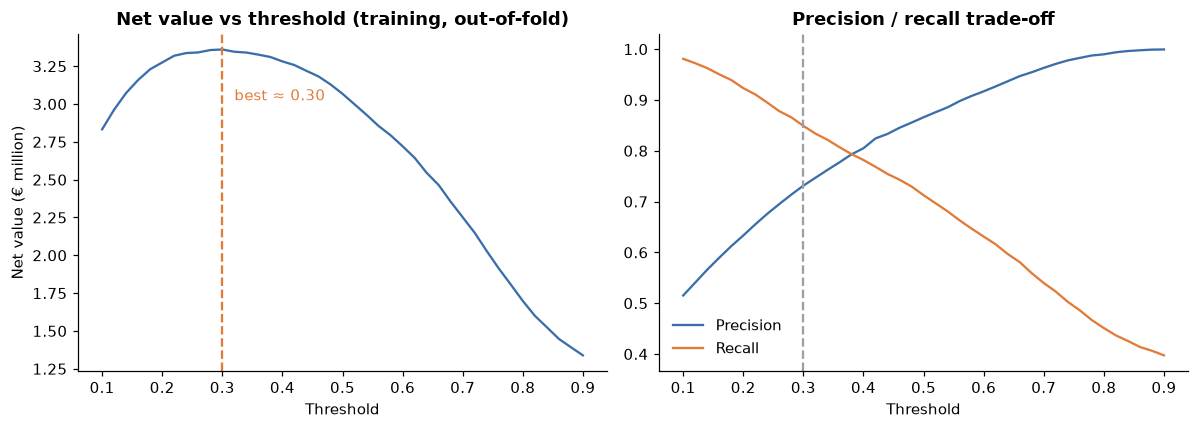

Chosen threshold: 0.3


In [10]:
best = models[best_name]
oof = cross_val_predict(best, X_train, y_train, groups=groups, cv=cv, method="predict_proba")[:, 1]
value_train = (train["adr"] * train["total_nights"].clip(lower=1)).values
GAIN_TP, COST_FP = 0.50, 0.20
def net_value(y, p, v, thr):
    flag = p >= thr
    return (GAIN_TP * v[flag & (y == 1)]).sum() - (COST_FP * v[flag & (y == 0)]).sum()
thrs = np.round(np.arange(0.10, 0.91, 0.02), 2)
nv = [net_value(y_train.values, oof, value_train, t) for t in thrs]
best_thr = float(thrs[int(np.argmax(nv))])
prec_c = [precision_score(y_train, oof >= t) for t in thrs]
rec_c = [recall_score(y_train, oof >= t) for t in thrs]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(thrs, np.array(nv) / 1e6, color=BLUE); ax[0].axvline(best_thr, ls="--", color=ORANGE)
ax[0].set(title="Net value vs threshold (training, out-of-fold)", xlabel="Threshold", ylabel="Net value (€ million)")
ax[0].text(best_thr + 0.02, max(nv) / 1e6 * 0.9, f"best ≈ {best_thr:.2f}", color=ORANGE)
ax[1].plot(thrs, prec_c, label="Precision", color=BLUE); ax[1].plot(thrs, rec_c, label="Recall", color=ORANGE)
ax[1].axvline(best_thr, ls="--", color=GREY); ax[1].set(title="Precision / recall trade-off", xlabel="Threshold"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG + "fig12_threshold.png", bbox_inches="tight"); plt.show()
print("Chosen threshold:", best_thr)

How the best threshold changes if the costs are different:

In [11]:
sens = []
for cfp in [0.05, 0.10, 0.20, 0.35, 0.50]:
    COST_FP = cfp
    v = [net_value(y_train.values, oof, value_train, t) for t in thrs]
    sens.append({"FP cost (% of booking)": int(cfp * 100), "best threshold": thrs[int(np.argmax(v))]})
COST_FP = 0.20
pd.DataFrame(sens)

,FP cost (% of booking),best threshold
0,5,0.12
1,10,0.18
2,20,0.30
3,35,0.42
4,50,0.46


Random Forest on 2017 test at threshold 0.3:
{'accuracy': 0.776, 'precision': 0.714, 'recall': 0.702, 'f1': 0.708, 'roc_auc': 0.843, 'pr_auc': 0.8}


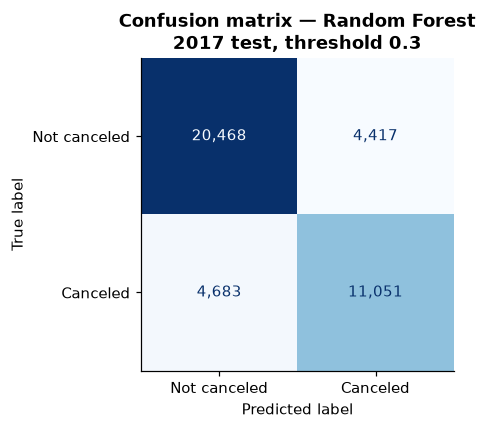

Net value on 2017 test (8 months): model €2.06M vs business rule €1.44M


In [12]:
p_best = probs[best_name]
final = scores(y_test, p_best, best_thr)
print(f"{best_name} on 2017 test at threshold {best_thr}:")
print({k: round(v, 3) for k, v in final.items()})
cm = confusion_matrix(y_test, p_best >= best_thr)
fig, ax = plt.subplots(figsize=(4.6, 4))
ConfusionMatrixDisplay(cm, display_labels=["Not canceled", "Canceled"]).plot(ax=ax, cmap="Blues", values_format=",", colorbar=False)
ax.set_title(f"Confusion matrix — {best_name}\n2017 test, threshold {best_thr}")
plt.tight_layout(); plt.savefig(FIG + "fig13_confusion.png", bbox_inches="tight"); plt.show()

value_test = (test["adr"] * test["total_nights"].clip(lower=1)).values
nv_test = net_value(y_test.values, p_best, value_test, best_thr)
nv_rule = net_value(y_test.values, r.values.astype(float), value_test, 0.5)
print(f"Net value on 2017 test (8 months): model €{nv_test/1e6:.2f}M vs business rule €{nv_rule/1e6:.2f}M")

## 7. Risk tiers
Three groups (High, Medium, Low) are easier for staff to use than a probability.

In [13]:
tier = pd.cut(p_best, [0, 0.3, 0.7, 1.0], labels=["Low (<30%)", "Medium (30–70%)", "High (>70%)"], include_lowest=True)
tiers = pd.DataFrame({"tier": tier, "y": y_test.values}).groupby("tier", observed=True)["y"].agg(
    bookings="size", actual_cancel_rate="mean")
tiers["share_of_bookings"] = tiers["bookings"] / tiers["bookings"].sum()
tiers["share_of_all_cancellations"] = pd.DataFrame({"tier": tier, "y": y_test.values}).groupby("tier", observed=True)["y"].sum() / y_test.sum()
tiers.round(3).to_csv("../reports/results_tiers.csv")
tiers.round(3)

,bookings,actual_cancel_rate,share_of_bookings,share_of_all_cancellations
tier,,,,
Low (<30%),25151,0.186,0.619,0.298
Medium (30–70%),8889,0.592,0.219,0.335
High (>70%),6579,0.879,0.162,0.368


## 8. Feature importance
Permutation importance: shuffle one column at a time on the 2017 test set and see how much ROC-AUC drops. A big drop means the model relies on that column.

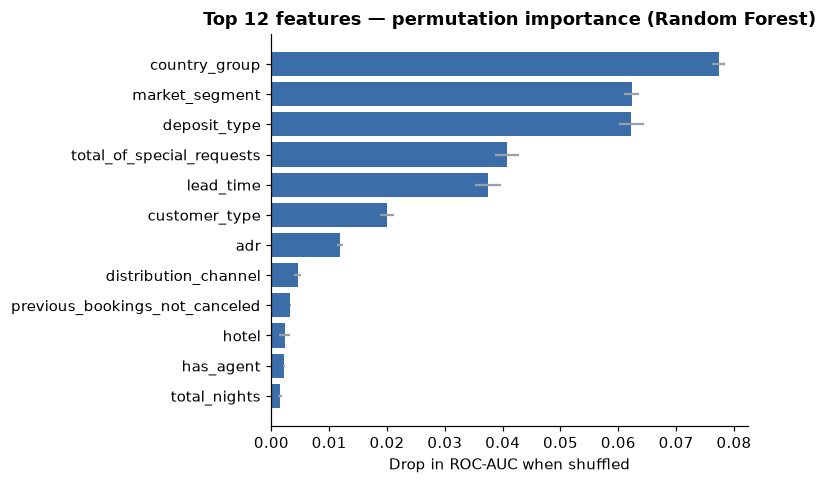

country_group                     0.077328
market_segment                    0.062288
deposit_type                      0.062206
total_of_special_requests         0.040703
lead_time                         0.037399
customer_type                     0.019915
adr                               0.011846
distribution_channel              0.004527
previous_bookings_not_canceled    0.003246
hotel                             0.002305
has_agent                         0.002200
total_nights                      0.001506
dtype: float64

In [14]:
sample = X_test.sample(10000, random_state=SEED); ys = y_test.loc[sample.index]
pi = permutation_importance(best, sample, ys, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=sample.columns).sort_values(ascending=False)
imp.round(4).to_csv("../reports/results_importance.csv")
top = imp.head(12)[::-1]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top.index, top.values, color=BLUE, xerr=pd.Series(pi.importances_std, index=sample.columns)[top.index], ecolor=GREY)
ax.set(title=f"Top 12 features — permutation importance ({best_name})", xlabel="Drop in ROC-AUC when shuffled")
plt.tight_layout(); plt.savefig(FIG + "fig14_importance.png", bbox_inches="tight"); plt.show()
imp.head(12)

Logistic regression coefficients (standardized features) show whether a feature raises or lowers the risk.

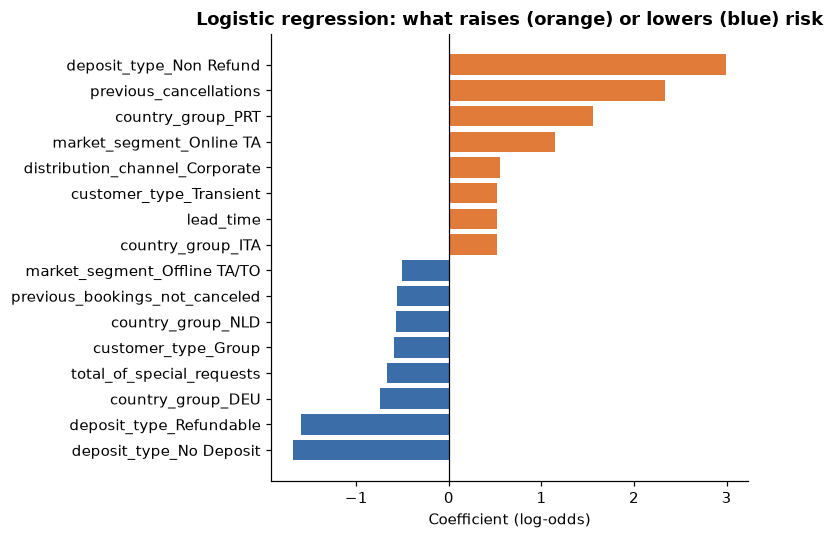

In [15]:
lr = fitted["Logistic Regression"]
names = lr.named_steps["pre"].get_feature_names_out()
coef = pd.Series(lr.named_steps["model"].coef_[0], index=[n.split("__", 1)[1] for n in names])
show = pd.concat([coef.nlargest(8), coef.nsmallest(8)]).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(show.index, show.values, color=[ORANGE if v > 0 else BLUE for v in show.values])
ax.axvline(0, color="black", lw=.8)
ax.set(title="Logistic regression: what raises (orange) or lowers (blue) risk", xlabel="Coefficient (log-odds)")
plt.tight_layout(); plt.savefig(FIG + "fig15_lr_coef.png", bbox_inches="tight"); plt.show()

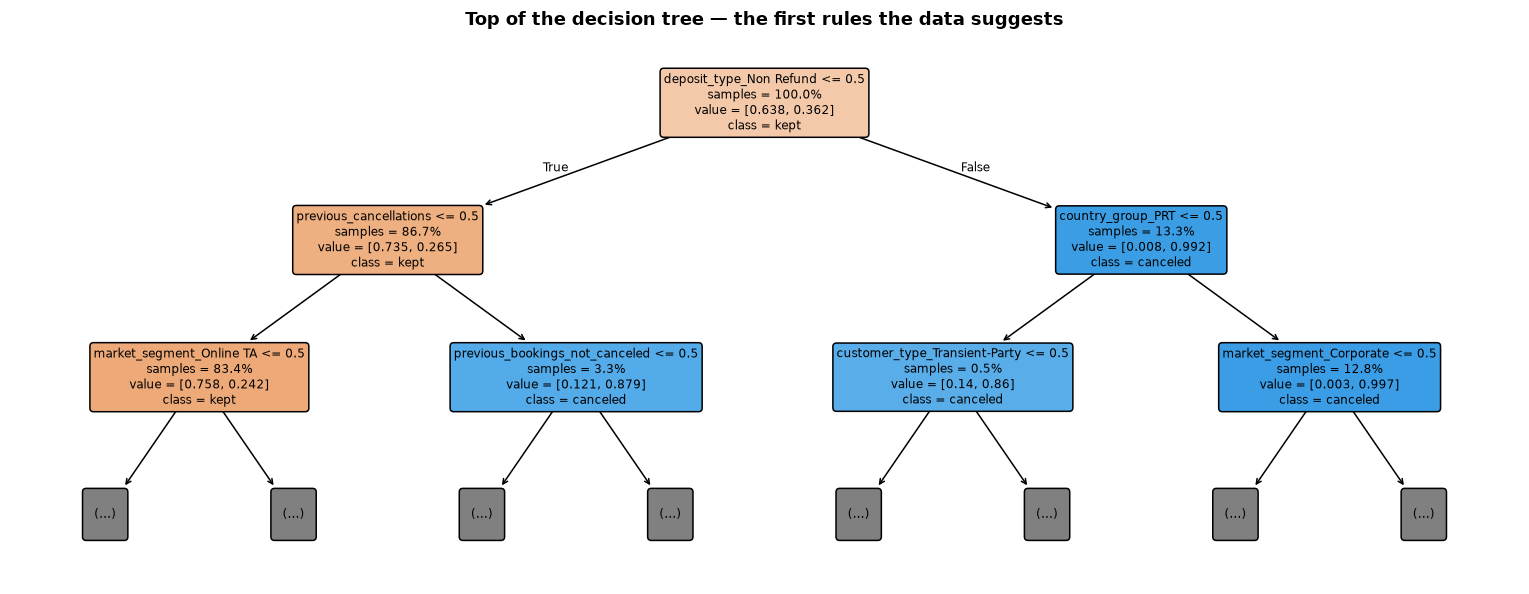

In [16]:
dt = fitted["Decision Tree (depth 8)"]
fig, ax = plt.subplots(figsize=(14, 5.5))
plot_tree(dt.named_steps["model"], max_depth=2, feature_names=[n.split("__", 1)[1] for n in dt.named_steps["pre"].get_feature_names_out()],
          class_names=["kept", "canceled"], filled=True, impurity=False, proportion=True, rounded=True, fontsize=8, ax=ax)
ax.set_title("Top of the decision tree — the first rules the data suggests")
plt.tight_layout(); plt.savefig(FIG + "fig16_tree.png", bbox_inches="tight"); plt.show()

## 9. Error analysis

In [17]:
ev = test[["hotel", "market_segment", "deposit_type", "lead_time", "customer_type"]].copy()
ev["y"] = y_test.values; ev["pred"] = (p_best >= best_thr).astype(int)
ev["lead_bin"] = pd.cut(ev["lead_time"], [-1, 7, 30, 90, 180, 800], labels=["0–7", "8–30", "31–90", "91–180", "180+"])
def seg_metrics(g):
    return pd.Series({"bookings": len(g), "cancel_rate": g.y.mean(),
                      "recall": recall_score(g.y, g.pred, zero_division=0), "precision": precision_score(g.y, g.pred, zero_division=0)})
err = pd.concat({c: ev.groupby(c, observed=True)[["y", "pred"]].apply(seg_metrics) for c in ["hotel", "market_segment", "lead_bin"]})
err = err[err["bookings"] >= 200].round(3)
err.to_csv("../reports/results_errors.csv")
err

bookings  cancel_rate  recall  precision
hotel          City Hotel      27446.0        0.426   0.765      0.715
               Resort Hotel    13173.0        0.308   0.523      0.714
market_segment Complementary     207.0        0.145   0.100      0.333
               Corporate        1558.0        0.255   0.688      0.838
               Direct           4622.0        0.155   0.270      0.497
               Groups           5845.0        0.582   0.978      0.921
               Offline TA/TO    5658.0        0.338   0.948      0.860
               Online TA       22621.0        0.409   0.587      0.603
lead_bin       0–7              5776.0        0.087   0.201      0.356
               8–30             6351.0        0.306   0.547      0.565
               31–90            9403.0        0.423   0.712      0.692
               91–180          10687.0        0.466   0.769      0.734
               180+             8402.0        0.515   0.745      0.809

In [18]:
fn = ev[(ev.y == 1) & (ev.pred == 0)]; tp = ev[(ev.y == 1) & (ev.pred == 1)]
print("Missed cancellations (false negatives):", len(fn))
print("  median lead time — missed:", fn.lead_time.median(), "| caught:", tp.lead_time.median())
print("  share Online TA — missed:", round((fn.market_segment == 'Online TA').mean(), 2), "| caught:", round((tp.market_segment == 'Online TA').mean(), 2))

Missed cancellations (false negatives): 4683
  median lead time — missed: 83.0 | caught: 129.0
  share Online TA — missed: 0.82 | caught: 0.49


## 10. Robustness checks

In [19]:
checks = []
def quick(name, Xtr, ytr, Xte, yte, cat, num):
    pre = ColumnTransformer([("num", SimpleImputer(strategy="median"), num),
                             ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), cat)])
    est = models[best_name].named_steps["model"]
    pipe = Pipeline([("pre", pre), ("model", type(est)(**est.get_params()))]).fit(Xtr[cat + num], ytr)
    p = pipe.predict_proba(Xte[cat + num])[:, 1]
    checks.append({"check": name, "test ROC-AUC": roc_auc_score(yte, p), "test PR-AUC": average_precision_score(yte, p)})

quick("Main model (time split)", train, y_train, test, y_test, CAT, NUM)
# (a) leakage demonstration: add the post-booking columns
leak_cat = CAT + ["assigned_room_type"]; leak_num = NUM + ["booking_changes", "required_car_parking_spaces"]
quick("WITH leaky columns (room/parking/changes) — not usable", train, y_train, test, y_test, leak_cat, leak_num)
# (b) without country (possible data-entry bias)
quick("Without country features", train, y_train, test, y_test, [c for c in CAT if c != "country_group"], NUM)
# (c) de-duplicated data
dd = df[df["is_duplicate"] == 0]; trd, ted = dd[dd.arrival_date < "2017-01-01"], dd[dd.arrival_date >= "2017-01-01"]
quick("De-duplicated data", trd, trd[TARGET], ted, ted[TARGET], CAT, NUM)
# (d) random split instead of time split (shows optimism)
trr, ter = train_test_split(df, test_size=0.3, stratify=df[TARGET], random_state=SEED)
quick("Random 70/30 split (duplicates can leak)", trr, trr[TARGET], ter, ter[TARGET], CAT, NUM)
checks_df = pd.DataFrame(checks).set_index("check").round(3)
checks_df.to_csv("../reports/results_checks.csv")
checks_df

,test ROC-AUC,test PR-AUC
check,,
Main model (time split),0.843,0.800
WITH leaky columns (room/parking/changes) — not usable,0.864,0.819
Without country features,0.822,0.781
De-duplicated data,0.783,0.615
Random 70/30 split (duplicates can leak),0.941,0.920


## 11. Save results

In [20]:
results.update({"best_model": best_name, "threshold": best_thr,
                "test_at_threshold": {k: round(v, 4) for k, v in final.items()},
                "confusion_matrix": cm.tolist(), "net_value_test_model_eur": round(nv_test), "net_value_test_rule_eur": round(nv_rule),
                "n_train": len(train), "n_test": len(test), "cancel_rate_train": round(y_train.mean(), 4), "cancel_rate_test": round(y_test.mean(), 4),
                "threshold_sensitivity": sens})
json.dump(results, open("../reports/key_results.json", "w"), indent=2, default=float)
results

{'best_model': 'Random Forest',
 'threshold': 0.3,
 'test_at_threshold': {'accuracy': 0.776,
  'precision': 0.7144,
  'recall': 0.7024,
  'f1': 0.7084,
  'roc_auc': 0.843,
  'pr_auc': 0.7998},
 'confusion_matrix': [[20468, 4417], [4683, 11051]],
 'net_value_test_model_eur': 2059900,
 'net_value_test_rule_eur': 1443177,
 'n_train': 78587,
 'n_test': 40619,
 'cancel_rate_train': np.float64(0.3622),
 'cancel_rate_test': np.float64(0.3874),
 'threshold_sensitivity': [{'FP cost (% of booking)': 5,
   'best threshold': np.float64(0.12)},
  {'FP cost (% of booking)': 10, 'best threshold': np.float64(0.18)},
  {'FP cost (% of booking)': 20, 'best threshold': np.float64(0.3)},
  {'FP cost (% of booking)': 35, 'best threshold': np.float64(0.42)},
  {'FP cost (% of booking)': 50, 'best threshold': np.float64(0.46)}]}